# gm/ID characterisation, sky130 nfet_01v8 / pfet_01v8

Adapted from the IHP SG13CMOS5L evaluation script by Boris Murmann and Harald Pretl (Apache License 2.0). Reads the `.mat` tables (indexed L, VGS, VDS, VSB); f_T includes the gate overlap capacitances when the table has `CGSO`/`CGDO`.

In [1]:
devices = ['nfet_01v8', 'pfet_01v8']
choice = 0

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

os.makedirs("overview/plots", exist_ok=True)

In [3]:
VDS1 = 0.9
VSB1 = 0.0
gmid_lim = 25
fig_prefix = {0: "SKY130_NFET01V8", 1: "SKY130_PFET01V8"}[choice]

In [4]:
d = loadmat(devices[choice] + '.mat', squeeze_me=True, struct_as_record=False)[devices[choice]]

l_um = d.L
vgs, vds, vsb = d.VGS, d.VDS, d.VSB
W = float(d.W)
T = float(d.TEMP)
k = 1.380649e-23

def ix(vec, val):
    return int(np.argmin(np.abs(vec - val)))

iVD, iVB = ix(vds, VDS1), ix(vsb, VSB1)
print(d.INFO)
print("array shape (L, VGS, VDS, VSB):", d.ID.shape)
print("L (um):", l_um)
print(f"plotting at VDS = {vds[iVD]:g} V, VSB = {vsb[iVB]:g} V")

sky130A nfet_01v8, 130nm CMOS, BSIM4
array shape (L, VGS, VDS, VSB): (12, 73, 73, 5)
L (um): [ 0.15  0.2   0.3   0.4   0.5   1.    1.5   2.    3.    4.    5.   10.  ]
plotting at VDS = 0.9 V, VSB = 0 V


In [5]:
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=plt.cm.viridis(np.linspace(0, 0.9, len(l_um))))
plt.rcParams['legend.framealpha'] = 1

def sl(name):
    # (L, VGS, VDS, VSB) at VDS1 / VSB1 -> (VGS, L); abs() folds the pfet sign
    return np.abs(getattr(d, name))[:, :, iVD, iVB].T

with np.errstate(divide='ignore', invalid='ignore'):
    ID, GM, GDS, CGG, STH, SFL = (sl(n) for n in ('ID', 'GM', 'GDS', 'CGG', 'STH', 'SFL'))
    gm_id = GM / ID
    have_cov = hasattr(d, 'CGSO') and hasattr(d, 'CGDO')
    cgt = CGG + sl('CGSO') + sl('CGDO') if have_cov else CGG
    ft = GM / cgt / 2 / np.pi

print("fT uses Cgg + Cgso + Cgdo" if have_cov else "fT uses Cgg only (no CGSO/CGDO in the .mat)")

legend_kw = dict(loc='center right', bbox_to_anchor=(1.2, 0.5), title='L (µm)',
                 labels=[f"{x:g}" for x in l_um])
title_all = devices[choice] + r', $V_\mathrm{DS}$=' + str(VDS1) + r'V, $V_\mathrm{SB}$=' + str(VSB1) + 'V'

fT uses Cgg + Cgso + Cgdo


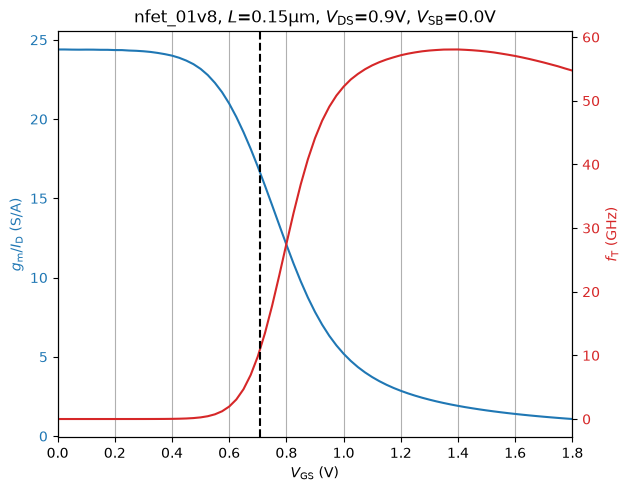

In [6]:
# plot gm/ID and fT versus gate bias
iL1 = int(np.argmin(l_um)); L1 = l_um[iL1]
gm_id1, ft1 = gm_id[:, iL1], ft[:, iL1]
title1 = devices[choice] + ', $L$=' + f"{L1:g}" + r'µm, $V_\mathrm{DS}$=' + str(VDS1) + r'V, $V_\mathrm{SB}$=' + str(VSB1) + 'V'

fig, ax1 = plt.subplots()
ax1.grid(axis='x')
ax1.set_xlabel(r'$V_\mathrm{GS}$ (V)')
color = 'tab:blue'
ax1.set_ylabel(r'$g_\mathrm{m}/I_\mathrm{D}$ (S/A)', color=color)
ax1.plot(vgs, gm_id1, color=color)
ax1.tick_params(axis='y', labelcolor=color)
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel(r'$f_\mathrm{T}$ (GHz)', color=color)
ax2.plot(vgs, ft1/1e9, color=color)
ax2.tick_params(axis='y', labelcolor=color)
fig.tight_layout()
plt.title(title1)
plt.xlim(0, vgs.max())
plt.axvline(x=abs(d.VT[iL1, 0, iVD, iVB]), color='k', linestyle='--')
plt.show()
fig.savefig(f"overview/plots/{fig_prefix}_gmID_fT_VGS.eps", bbox_inches='tight')

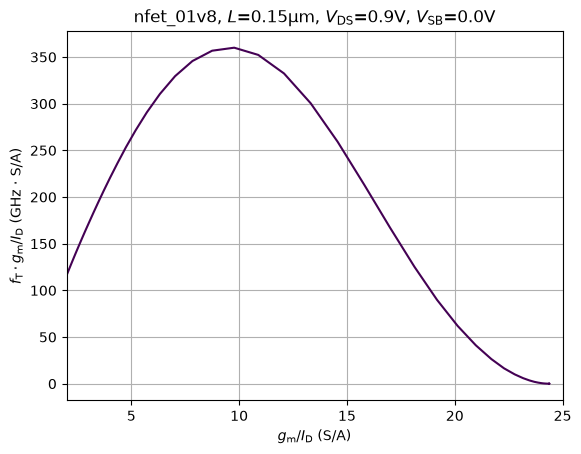

In [7]:
# plot product of gm/ID and fT versus gm/ID
fig, ax1 = plt.subplots()
plt.plot(gm_id1, gm_id1*ft1/1e9)
plt.xlim(2, gmid_lim)
plt.xlabel(r'$g_\mathrm{m}/I_\mathrm{D}$ (S/A)')
plt.ylabel(r'$f_\mathrm{T} \cdot g_\mathrm{m}/I_\mathrm{D}$ (GHz $\cdot$ S/A)')
plt.title(title1)
plt.grid()
plt.show()
fig.savefig(f"overview/plots/{fig_prefix}_fTgmID_gmID.eps", bbox_inches='tight')

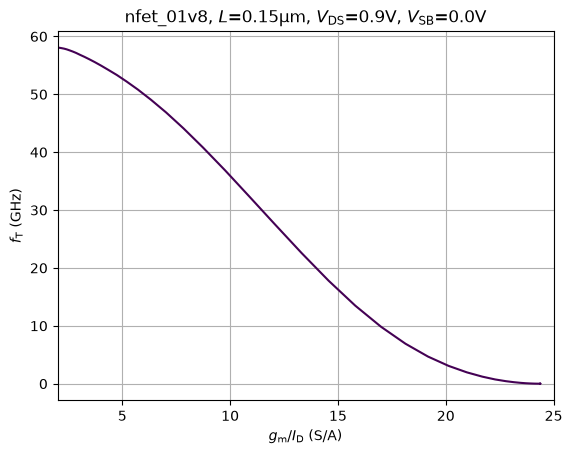

In [8]:
# plot fT versus gm/ID
plt.plot(gm_id1, ft1/1e9)
plt.xlim(2, gmid_lim)
plt.xlabel(r'$g_\mathrm{m}/I_\mathrm{D}$ (S/A)')
plt.ylabel(r'$f_\mathrm{T}$ (GHz)')
plt.title(title1)
plt.grid()
plt.show()

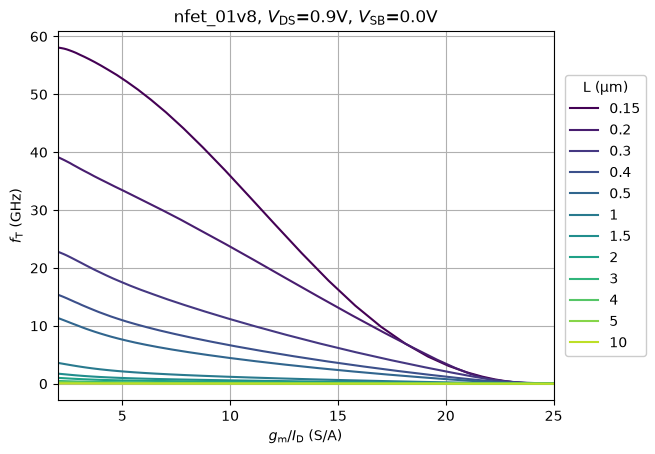

In [9]:
# plot fT versus gm/ID for all L
fig, ax = plt.subplots()
ax.plot(gm_id, ft/1e9)
ax.legend(**legend_kw)
plt.xlim(2, gmid_lim)
plt.xlabel(r'$g_\mathrm{m}/I_\mathrm{D}$ (S/A)')
plt.ylabel(r'$f_\mathrm{T}$ (GHz)')
plt.title(title_all)
plt.grid()
plt.show()
fig.savefig(f"overview/plots/{fig_prefix}_fT_gmID.eps", bbox_inches='tight')

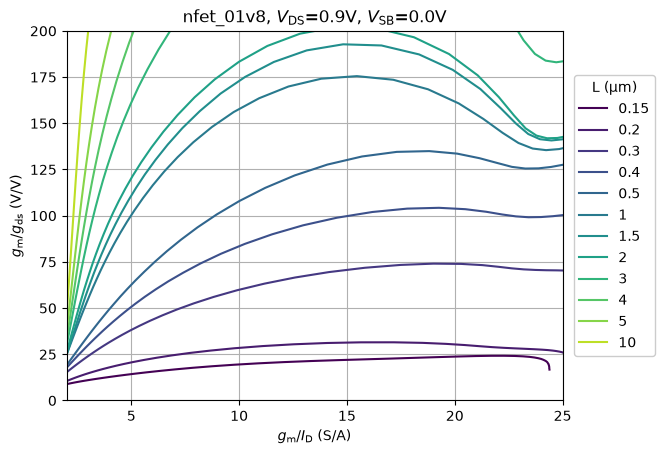

In [10]:
# plot gm/gds versus gm/ID for all L
with np.errstate(divide='ignore', invalid='ignore'):
    gm_gds = GM / GDS

fig, ax = plt.subplots()
ax.plot(gm_id, gm_gds)
ax.legend(**legend_kw)
plt.xlim(2, gmid_lim)
plt.ylim(0, 200)
plt.xlabel(r'$g_\mathrm{m}/I_\mathrm{D}$ (S/A)')
plt.ylabel(r'$g_\mathrm{m}/g_\mathrm{ds}$ (V/V)')
plt.title(title_all)
plt.grid()
plt.show()
fig.savefig(f"overview/plots/{fig_prefix}_gmgds_gmID.eps", bbox_inches='tight')

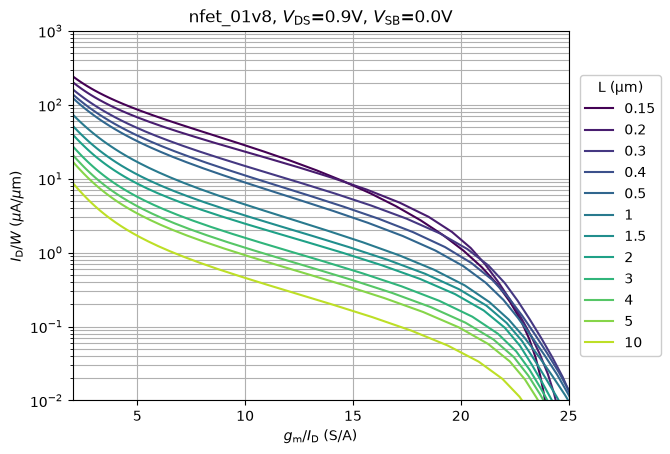

In [11]:
# plot Id/W (Jd) versus gm/ID for all L
jd = ID / W   # A/m, numerically equal to uA/um

fig, ax = plt.subplots()
ax.semilogy(gm_id, jd)
ax.legend(**legend_kw)
plt.xlim(2, gmid_lim)
if choice == 1:
    plt.ylim(1e-3, 1e2)
else:
    plt.ylim(1e-2, 1e3)
plt.xlabel(r'$g_\mathrm{m}/I_\mathrm{D}$ (S/A)')
plt.ylabel(r'$I_\mathrm{D}/W$ ($\mu$A/$\mu$m)')
plt.grid(which='minor')
plt.grid(which='major')
plt.title(title_all)
plt.show()
fig.savefig(f"overview/plots/{fig_prefix}_IDW_gmID.eps", bbox_inches='tight')

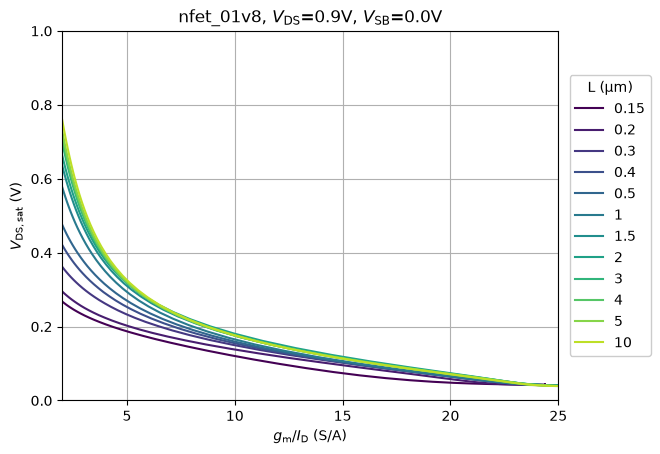

In [12]:
# plot Vdsat versus gm/ID for all L
if hasattr(d, 'VDSAT'):
    vdsat = sl('VDSAT')
    ylabel = r'$V_\mathrm{DS,sat}$ (V)'
    ylim = (0, 1)
else:
    vdsat = vgs[:, None] - np.abs(d.VT)[:, :, iVD, iVB].T
    ylabel = r'$V_\mathrm{GS}-V_\mathrm{T}$ (V)  [stand-in for $V_\mathrm{DS,sat}$]'
    ylim = (-0.5, 1)

fig, ax = plt.subplots()
ax.plot(gm_id, vdsat)
ax.legend(**legend_kw)
plt.xlim(2, gmid_lim)
plt.ylim(*ylim)
plt.xlabel(r'$g_\mathrm{m}/I_\mathrm{D}$ (S/A)')
plt.ylabel(ylabel)
plt.grid(which='minor')
plt.grid(which='major')
plt.title(title_all)
plt.show()
fig.savefig(f"overview/plots/{fig_prefix}_Vdssat_gmID.eps", bbox_inches='tight')

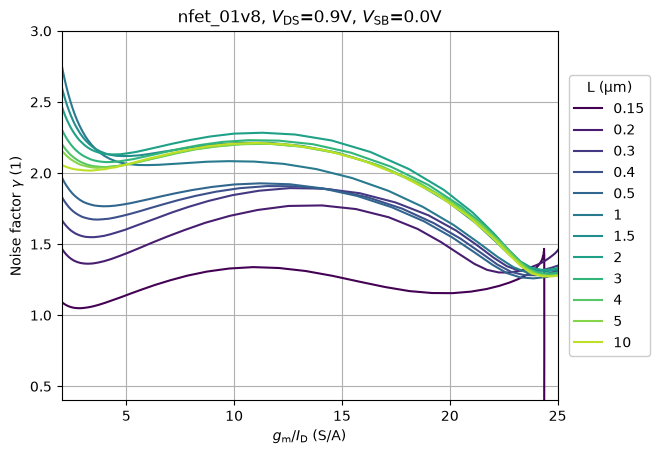

In [13]:
# plot noise factor gamma versus gm/ID for all L
with np.errstate(divide='ignore', invalid='ignore'):
    gamma = STH / (4 * k * T * GM)

fig, ax = plt.subplots()
ax.plot(gm_id, gamma)
ax.legend(**legend_kw)
plt.xlim(2, gmid_lim)
plt.ylim(0.4, 3.0)
plt.xlabel(r'$g_\mathrm{m}/I_\mathrm{D}$ (S/A)')
plt.ylabel(r'Noise factor $\gamma$ (1)')
plt.grid(which='minor')
plt.grid(which='major')
plt.title(title_all)
plt.show()
fig.savefig(f"overview/plots/{fig_prefix}_gamma_gmID.eps", bbox_inches='tight')

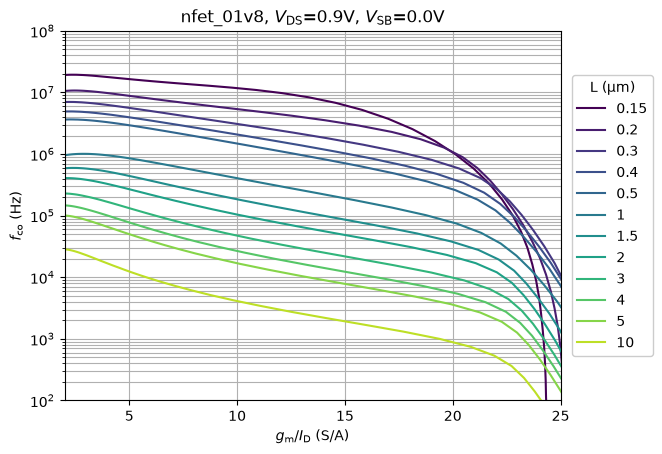

In [14]:
# plot flicker-noise corner frequency versus gm/ID for all L
with np.errstate(divide='ignore', invalid='ignore'):
    fco = SFL / STH

fig, ax = plt.subplots()
ax.semilogy(gm_id, fco)
ax.legend(**legend_kw)
plt.xlim(2, gmid_lim)
plt.ylim(1e2, 1e8)
plt.xlabel(r'$g_\mathrm{m}/I_\mathrm{D}$ (S/A)')
plt.ylabel(r'$f_\mathrm{co}$ (Hz)')
plt.grid(which='minor')
plt.grid(which='major')
plt.title(title_all)
plt.show()
fig.savefig(f"overview/plots/{fig_prefix}_fco_gmID.eps", bbox_inches='tight')